# Complaint2Concern
## Using pretrained complaint embeddings to catch acuity-relevant risk that structured triage may miss

### Clinical motivation
- Emergency triage decisions are safety-critical, and undertriage is often the most harmful error type.
- Structured intake fields are useful but may miss concern signals present in free-text chief complaint language.
- We use pretrained complaint embeddings as a second clinical lens and analyze disagreement with structured-only predictions.

### Hypothesis
Pretrained complaint embeddings improve acuity prediction and help identify cases where free text suggests more urgency than structured intake alone.

### Core questions
1. Does complaint text improve triage acuity prediction beyond structured features?
2. Which complaint clusters are associated with higher acuity?
3. Can text-vs-structure disagreement identify review-worthy cases?

## Data understanding and leakage guardrails

This is a triage-time task. All model inputs must be available at triage decision time.

- Allowed: intake structured variables, chief complaint text, prior history available at triage.
- Excluded as leakage: post-triage outcomes (for example `disposition`, `ed_los_hours`).

Missingness is handled with model pipelines (median/mode imputation in structured preprocessing).

In [1]:
#TODO:

# - see how the acuity is balanced !! test does not have target variables
# - missing values how are they treated?
# - UMAP to select better phrase representation
# - select and try other LM - clinicalBERT
# - predominant words in a cluster 


In [2]:
import os
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix, hstack
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.preprocessing import LabelEncoder

try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_OK = True
except Exception:
    MATPLOTLIB_OK = False

# Resolve project root (works in local Jupyter and in Kaggle if repo is copied).
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = None
for c in candidates:
    if (c / 'src').exists() and (c / 'configs').exists():
        PROJECT_ROOT = c
        break
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate PROJECT_ROOT with src/ and configs/.')

sys.path.append(str(PROJECT_ROOT))
print('PROJECT_ROOT:', PROJECT_ROOT)


PROJECT_ROOT: /Users/raquel_romao/Documents/3AIG_TriageKeggleCompetition/3AIG


In [3]:
from src.config import load_config
from src.data_io import load_train_test
from src.embeddings import encode_complaints
from src.features_structured import fit_transform_structured, infer_structured_columns
from src.features_text import fit_transform_tfidf
from src.preprocess import preprocess_text_series
from src.utils import make_classifier, set_seed

In [4]:
# Config
cfg = load_config(PROJECT_ROOT / 'configs/minilm_catboost.yaml')

# Optional Kaggle path override example:
# cfg['data']['kaggle_input_dir'] = '/kaggle/input/triagegeist'

DEV_SAMPLE_N = None  # Set an integer like 20000 for quick local iteration.
SEED = cfg['train'].get('seed', 42)
CV_MODE = 'stratified'  # 'stratified' or 'group_site'
N_SPLITS = 5
set_seed(SEED)

# merges original train and test to complaint text by patient id
train_df, test_df = load_train_test(cfg)
if DEV_SAMPLE_N is not None and DEV_SAMPLE_N < len(train_df):
    train_df = train_df.sample(DEV_SAMPLE_N, random_state=SEED).reset_index(drop=True)

id_col = cfg['data']['id_col']
target_col = cfg['data']['target_col']
text_col = cfg['data']['text_col']
leakage_cols = cfg['data'].get('leakage_columns', [])

print('train shape:', train_df.shape)
print('test shape :', test_df.shape)
print('target col :', target_col)
print('text col   :', text_col)
print('null text train:', round(train_df[text_col].isna().mean(), 4))
print('null text test :', round(test_df[text_col].isna().mean(), 4))
print('CV mode:', CV_MODE, '| folds:', N_SPLITS)


train shape: (80000, 66)
test shape : (20000, 63)
target col : triage_acuity
text col   : chief_complaint_raw
null text train: 0.0
null text test : 0.0
CV mode: stratified | folds: 5


Acuity distribution (train):


triage_acuity
1    0.040275
2    0.167988
3    0.361513
4    0.287750
5    0.142475
Name: proportion, dtype: float64

,missing_rate
shock_index,0.051825
pulse_pressure,0.051825
systolic_bp,0.051825
diastolic_bp,0.051825
mean_arterial_pressure,0.051825
respiratory_rate,0.038337
temperature_c,0.007175
hx_diabetes_type2,0.000000
hx_diabetes_type1,0.000000
disposition,0.000000


,heart_rate,respiratory_rate,temperature_c,spo2,systolic_bp,diastolic_bp,news2_score
triage_acuity,,,,,,,
1,119.2,28.0,38.9,85.9,82.6,52.15,14.0
2,108.7,23.0,38.5,92.0,100.4,63.30,10.0
3,93.0,18.0,37.7,96.0,126.0,76.90,2.0
4,84.1,16.0,37.2,98.0,132.0,80.00,0.0
5,76.8,15.0,36.9,99.0,128.1,78.80,0.0


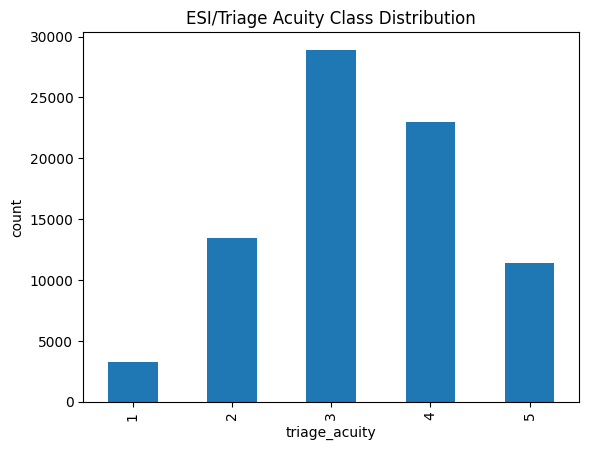

In [5]:
# Triage-focused EDA
print('Acuity distribution (train):')
display(train_df[target_col].value_counts(normalize=True).sort_index())

missingness = train_df.isna().mean().sort_values(ascending=False)
display(missingness.head(15).to_frame('missing_rate'))

# Vitals by acuity (median)
vitals = [c for c in ['heart_rate','respiratory_rate','temperature_c','spo2','systolic_bp','diastolic_bp','news2_score'] if c in train_df.columns]
if vitals:
    display(train_df.groupby(target_col)[vitals].median())

if MATPLOTLIB_OK:
    ax = train_df[target_col].value_counts().sort_index().plot(kind='bar', title='ESI/Triage Acuity Class Distribution')
    ax.set_xlabel('triage_acuity')
    ax.set_ylabel('count')
    plt.show()

## Complaint text preprocessing

We keep preprocessing lightweight and realistic for triage text:
- lowercase
- punctuation and whitespace cleanup
- optional normalization of common abbreviations
- keep most spelling noise intact to preserve realistic inputs

In [6]:
#TODO:
# - See if this is really necessary 
# Ines:  I wanted to check if there are abbreviations -> THERE ARE;  Maybe change thiss!!!! -> I would say this is doneeee
from collections import Counter

# Regex pattern for abbreviations (uppercase or dot-style)
abbr_pattern = r'\b(?:[A-Z]\.){2,}|\b[A-Z]{2,}\b'

# NOTE: keep this analysis in temporary variables to avoid leaking list objects into model features.
abbr_series = train_df[text_col].apply(lambda x: re.findall(abbr_pattern, str(x)))
all_abbr = [abbr for sublist in abbr_series for abbr in sublist]

# Count occurrences
abbr_summary = Counter(all_abbr)

# Convert to DataFrame for nicer display
summary_df = pd.DataFrame(abbr_summary.items(), columns=['Abbreviation', 'Count']).sort_values(by='Count', ascending=False)

# Defensive cleanup in case an earlier run created this helper column
for _tmp_col in ['abbreviations']:
    if _tmp_col in train_df.columns:
        train_df = train_df.drop(columns=[_tmp_col])
    if _tmp_col in test_df.columns:
        test_df = test_df.drop(columns=[_tmp_col])

print(summary_df)


   Abbreviation  Count
0           UTI    917
8           STI    650
3           LOC    526
7            AF    355
9           MVA    259
4            GI    246
6           DKA    208
5            BP    205
11          IBS    201
10       NSTEMI    193
1          URTI    191
2           ECG    173
12        STEMI     48
13          GCS     45


In [7]:
ABBREV_MAP = {
    "UTI": "Urinary Tract Infection",
    "URTI": "Upper Respiratory Tract Infection",
    "LOC": "Loss of Consciousness",
    "GI": "Gastrointestinal",
    "BP": "Blood Pressure",
    "DKA": "Diabetic Ketoacidosis",
    "AF": "Atrial Fibrillation",
    "MVA": "Motor Vehicle Accident",
    "STI": "Sexually Transmitted Infection",
    "NSTEMI": "Non-ST-Elevation Myocardial Infarction",
    "IBS": "Irritable Bowel Syndrome",
    "STEMI": "ST-Elevation Myocardial Infarction",
    "GCS": "Glasgow Coma Scale",
    "ECG": "Electrocardiogram"
}

def normalize_abbrev(text: str) -> str:
    t = '' if text is None else str(text).lower()
    for k, v in ABBREV_MAP.items():
        t = re.sub(rf'\b{re.escape(k)}\b', v.lower(), t)
    return t

train_df[text_col] = train_df[text_col].fillna('').map(normalize_abbrev)
test_df[text_col] = test_df[text_col].fillna('').map(normalize_abbrev)

display(train_df[[text_col]].head(10))

,chief_complaint_raw
0,"thunderclap headache, worsening with movement"
1,"contraception advice, intermittent"
2,"general health question, intermittent"
3,"erythema migrans tick bite, intermittent"
4,"cellulitis localised, intermittent"
5,shingles with pain with associated nausea
6,minor skin rash with rigors
7,substance intoxication，worsening over hours
8,"small cut wound check, intermittent"
9,minor facial laceration with rigors


In [8]:
#TODO:

# - See what is labelEncoder()
# - stratify :
###  Ines: the division is considering the y: distribution  (in the stratified triage acuity is being considered)

In [9]:
# Prepare split (cross-validation setup)
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(train_df[target_col].astype(str))


def make_splitter(df, y, mode='stratified', n_splits=5, seed=42):
    if mode == 'group_site' and 'site_id' in df.columns:
        gkf = GroupKFold(n_splits=n_splits)
        return list(gkf.split(df, y, groups=df['site_id']))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(skf.split(df, y))


splits = make_splitter(train_df, y_all, mode=CV_MODE, n_splits=N_SPLITS, seed=SEED)
print(f"Built {len(splits)} CV folds")
print("y_all:", Counter(y_all))

# Reference fold for exploratory cells (TF-IDF inspection, UMAP, etc.)
ref_tr_idx, ref_va_idx = splits[0]
tr = train_df.iloc[ref_tr_idx].reset_index(drop=True)
va = train_df.iloc[ref_va_idx].reset_index(drop=True)
y_tr = y_all[ref_tr_idx]
y_va = y_all[ref_va_idx]

print('reference fold train split:', tr.shape)
print('reference fold valid split:', va.shape)


Built 5 CV folds
y_all: Counter({np.int64(2): 28921, np.int64(3): 23020, np.int64(1): 13439, np.int64(4): 11398, np.int64(0): 3222})
reference fold train split: (64000, 66)
reference fold valid split: (16000, 66)


In [10]:
# ClinicalBERT test is intentionally disabled in this notebook version.
# We keep MiniLM as the active embedding model for the CV experiments.


In [11]:
# (intentionally left minimal to preserve notebook structure)


In [12]:
# Structured feature preprocessing
structured_cols = infer_structured_columns(
    tr,
    target_col=target_col,
    text_col=text_col,
    id_col=id_col,
    explicit_drop_cols=leakage_cols,
)

structured_pre, x_tr_struct, x_va_struct = fit_transform_structured(tr[structured_cols], va[structured_cols])
print('structured feature count:', x_tr_struct.shape[1])

structured feature count: 178


In [13]:
tr.head()

,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,hx_hypothyroidism,hx_hyperthyroidism,hx_hiv,hx_coagulopathy,hx_immunosuppressed,hx_pregnant,hx_substance_use_disorder,hx_coronary_artery_disease,hx_stroke_prior,hx_peripheral_vascular_disease
0,TG-UXRGA9UCO,SITE-TMP-01,NURSE-0033,walk-in,6,Monday,5,spring,morning,43,...,1,1,0,0,1,0,0,0,0,0
1,TG-B19DBBS2G,SITE-HEL-01,NURSE-0001,walk-in,6,Thursday,4,spring,morning,72,...,1,0,0,0,1,0,1,1,0,0
2,TG-GZ97W7M6V,SITE-HEL-02,NURSE-0005,walk-in,8,Saturday,4,spring,morning,82,...,0,1,1,0,0,0,0,1,1,1
3,TG-THIB2TN9Q,SITE-HEL-02,NURSE-0026,police,7,Sunday,3,spring,morning,50,...,0,0,1,0,1,0,0,0,0,1
4,TG-J3U3LQ2QY,SITE-HEL-02,NURSE-0044,walk-in,5,Tuesday,5,spring,night,62,...,1,1,0,1,1,0,1,1,1,0


# Compare Text Representations (Ines)

## TF-IFF

In [14]:
import umap
import matplotlib.pyplot as plt

tfidf_vec, x_tr_tfidf, x_va_tfidf = fit_transform_tfidf(
    tr[text_col],
    va[text_col],
    max_features=25000,
    ngram_range=(1, 2),
)

print(x_tr_tfidf.shape, x_va_tfidf.shape)

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(64000, 2941) (16000, 2941)


In [15]:
tfidf_vec

,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",'unicode'
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Con

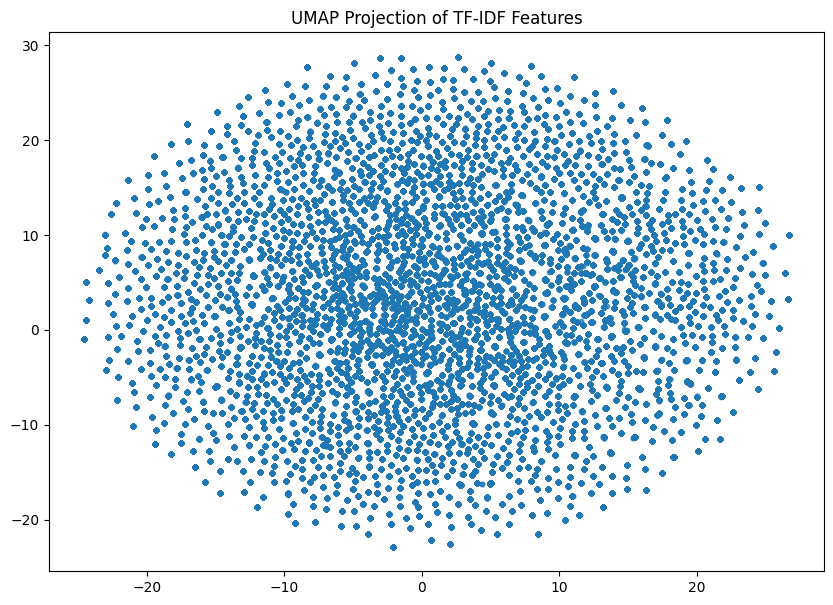

In [16]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, metric='cosine', random_state=42)
embedding = reducer.fit_transform(x_tr_tfidf)

plt.figure(figsize=(10, 7))
plt.scatter(embedding[:, 0], embedding[:, 1], s=10, alpha=0.7)
plt.title("UMAP Projection of TF-IDF Features")
plt.show()

## Embeddings

In [17]:
# Embeddings are extracted with src.embeddings.encode_complaints (MiniLM) in this notebook.
# Keeping this section for narrative continuity with earlier experiments.


## Baselines and fusion models

We train and compare:
1. Structured-only
2. Text-only (TF-IDF + linear model)
3. Structured + TF-IDF
4. Text-only pretrained embeddings
5. Structured + pretrained embeddings (Complaint2Concern fusion)

In [18]:
#TODO:

# - see how xgboost and catboost works
# - how is class imbalance worked around in make_classifier() para um multiclass problem 
# - no tunning of parameters here - model simplification + we only dividid our train and val once (only 20%) - we should divide our dataset differently / cross validation - we can then have a better probabiblity representative / medium - structure of the code will differ
# - understand TF-IDF  (inees DONE)
# - why csr_matrix - done (together DONE -> i think it is the sparsity)
# - see how sentence transformer works 
# - normalize embeddings?
# - make it explainable?
# - ADD CROSS VALIDATION (DONE)


### Ines Notes: 

Is this correct? 

Understand TF-IDF (Term Frequency-Inverse Document Frequency).
https://www.geeksforgeeks.org/machine-learning/understanding-tf-idf-term-frequency-inverse-document-frequency/

TF =  term frequency
IDF =  Inverse document frequency -> reduces the importance of 


What is the fit doing.?
it is finding the vocabulary (which words are different)

it is counting the words


What is the transform doing?

transforming the word into numerical representation. Each word is transformed to the score obtained previously


Why do we need to be carefull with sparsity?

Because the number of columns is related to the number of different words found (vocabulary).


In [19]:
# 1) Structured-only
# 2) Text-only TF-IDF + linear model
# 3) Structured + TF-IDF
# 4) Text-only pretrained embeddings
# 5) Structured + pretrained embeddings (main fusion)

classes_int = np.asarray(label_encoder.classes_).astype(int)
high_mask = classes_int <= 2
n = len(train_df)
n_classes = len(label_encoder.classes_)

emb_model_name = cfg['embeddings'].get('model_name', 'sentence-transformers/all-MiniLM-L6-v2')
emb_batch_size = cfg['embeddings'].get('batch_size', 64)
emb_backend = cfg['embeddings'].get('backend', 'sentence_transformers')

# OOF containers
oof = {
    'true_enc': y_all.copy(),
    'pred_structured': np.full(n, -1, dtype=int),
    'pred_text_tfidf': np.full(n, -1, dtype=int),
    'pred_structured_tfidf': np.full(n, -1, dtype=int),
    'pred_text_emb': np.full(n, -1, dtype=int),
    'pred_fusion': np.full(n, -1, dtype=int),
    'proba_structured': np.zeros((n, n_classes), dtype=float),
    'proba_text_emb': np.zeros((n, n_classes), dtype=float),
    'proba_fusion': np.zeros((n, n_classes), dtype=float),
}

# Interpretability containers (aggregated across folds)
interp_rows = []
interp_block_rows = []
tfidf_class_rows = []

cv_rows = []
ref_artifacts = {}

TOPK_GLOBAL = 80
TOPK_CLASS_TERMS = 20

for fold, (tr_idx, va_idx) in enumerate(splits, start=1):
    fold_start = time.time()

    tr_fold = train_df.iloc[tr_idx].reset_index(drop=True)
    va_fold = train_df.iloc[va_idx].reset_index(drop=True)
    y_tr_fold = y_all[tr_idx]
    y_va_fold = y_all[va_idx]

    struct_cols_fold = infer_structured_columns(
        tr_fold,
        target_col=target_col,
        text_col=text_col,
        id_col=id_col,
        explicit_drop_cols=leakage_cols,
    )
    struct_pre_fold, x_tr_struct_fold, x_va_struct_fold = fit_transform_structured(
        tr_fold[struct_cols_fold], va_fold[struct_cols_fold]
    )

    try:
        structured_feature_names = list(struct_pre_fold.get_feature_names_out())
    except Exception:
        structured_feature_names = [f'struct_{i}' for i in range(x_tr_struct_fold.shape[1])]

    # Structured-only
    structured_model = make_classifier(
        model_name='catboost',
        params={'iterations': 350, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
        n_classes=n_classes,
    )
    structured_model.fit(x_tr_struct_fold, y_tr_fold)
    pred_struct = np.asarray(structured_model.predict(x_va_struct_fold)).reshape(-1).astype(int)
    proba_struct = np.asarray(structured_model.predict_proba(x_va_struct_fold))

    # Structured-only importances
    try:
        fi_struct = np.asarray(structured_model.get_feature_importance())
        top_idx = np.argsort(fi_struct)[::-1][:TOPK_GLOBAL]
        for rank, idx in enumerate(top_idx, start=1):
            interp_rows.append({
                'fold': fold,
                'model': 'structured_only',
                'feature': structured_feature_names[idx],
                'importance': float(fi_struct[idx]),
                'rank': rank,
            })
    except Exception:
        pass

    # Text-only TF-IDF + LR
    tfidf_vec, x_tr_tfidf_fold, x_va_tfidf_fold = fit_transform_tfidf(
        tr_fold[text_col],
        va_fold[text_col],
        max_features=25000,
        ngram_range=(1, 2),
    )
    tfidf_model = LogisticRegression(max_iter=1200, solver='lbfgs')
    tfidf_model.fit(x_tr_tfidf_fold, y_tr_fold)
    pred_tfidf = tfidf_model.predict(x_va_tfidf_fold).astype(int)

    tfidf_feature_names = np.asarray(tfidf_vec.get_feature_names_out())

    # Text-only TF-IDF global importance + class terms
    coef_tfidf = np.asarray(tfidf_model.coef_)
    imp_tfidf = np.mean(np.abs(coef_tfidf), axis=0)
    top_idx = np.argsort(imp_tfidf)[::-1][:TOPK_GLOBAL]
    for rank, idx in enumerate(top_idx, start=1):
        interp_rows.append({
            'fold': fold,
            'model': 'text_tfidf_only',
            'feature': f"tfidf::{tfidf_feature_names[idx]}",
            'importance': float(imp_tfidf[idx]),
            'rank': rank,
        })

    for class_ix, class_label in enumerate(label_encoder.classes_):
        class_coef = coef_tfidf[class_ix]
        top_pos_idx = np.argsort(class_coef)[::-1][:TOPK_CLASS_TERMS]
        for rank, idx in enumerate(top_pos_idx, start=1):
            tfidf_class_rows.append({
                'fold': fold,
                'model': 'text_tfidf_only',
                'class_label': int(class_label),
                'term': tfidf_feature_names[idx],
                'coef': float(class_coef[idx]),
                'rank': rank,
            })

    # Structured + TF-IDF
    x_tr_struct_sparse = csr_matrix(x_tr_struct_fold)
    x_va_struct_sparse = csr_matrix(x_va_struct_fold)
    x_tr_struct_tfidf = hstack([x_tr_struct_sparse, x_tr_tfidf_fold]).tocsr()
    x_va_struct_tfidf = hstack([x_va_struct_sparse, x_va_tfidf_fold]).tocsr()
    struct_tfidf_model = LogisticRegression(max_iter=1200, solver='lbfgs')
    struct_tfidf_model.fit(x_tr_struct_tfidf, y_tr_fold)
    pred_struct_tfidf = struct_tfidf_model.predict(x_va_struct_tfidf).astype(int)

    mix_feature_names = np.array(structured_feature_names + [f"tfidf::{t}" for t in tfidf_feature_names])
    coef_mix = np.asarray(struct_tfidf_model.coef_)
    imp_mix = np.mean(np.abs(coef_mix), axis=0)
    top_idx = np.argsort(imp_mix)[::-1][:TOPK_GLOBAL]
    for rank, idx in enumerate(top_idx, start=1):
        interp_rows.append({
            'fold': fold,
            'model': 'structured_plus_tfidf',
            'feature': mix_feature_names[idx],
            'importance': float(imp_mix[idx]),
            'rank': rank,
        })

    # Structured + TF-IDF block importance
    s_dim = x_tr_struct_fold.shape[1]
    struct_mass = float(imp_mix[:s_dim].sum())
    tfidf_mass = float(imp_mix[s_dim:].sum())
    total_mass = struct_mass + tfidf_mass + 1e-12
    interp_block_rows.extend([
        {'fold': fold, 'model': 'structured_plus_tfidf', 'block': 'structured', 'importance': struct_mass, 'share': struct_mass / total_mass},
        {'fold': fold, 'model': 'structured_plus_tfidf', 'block': 'text_tfidf', 'importance': tfidf_mass, 'share': tfidf_mass / total_mass},
    ])

    # Text-only embeddings
    x_tr_emb_fold = encode_complaints(
        tr_fold[text_col],
        model_name=emb_model_name,
        batch_size=emb_batch_size,
        backend=emb_backend,
        normalize_embeddings=True,
    )
    x_va_emb_fold = encode_complaints(
        va_fold[text_col],
        model_name=emb_model_name,
        batch_size=emb_batch_size,
        backend=emb_backend,
        normalize_embeddings=True,
    )

    emb_text_model = make_classifier(
        model_name='lightgbm',
        params={'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 63},
        n_classes=n_classes,
    )
    emb_text_model.fit(x_tr_emb_fold, y_tr_fold)
    pred_emb_text = np.asarray(emb_text_model.predict(x_va_emb_fold)).reshape(-1).astype(int)
    proba_emb_text = np.asarray(emb_text_model.predict_proba(x_va_emb_fold))

    emb_dim_names = np.array([f'emb_{i:03d}' for i in range(x_tr_emb_fold.shape[1])])
    try:
        imp_emb = np.asarray(emb_text_model.feature_importances_)
        top_idx = np.argsort(imp_emb)[::-1][:TOPK_GLOBAL]
        for rank, idx in enumerate(top_idx, start=1):
            interp_rows.append({
                'fold': fold,
                'model': 'text_emb_only',
                'feature': emb_dim_names[idx],
                'importance': float(imp_emb[idx]),
                'rank': rank,
            })
    except Exception:
        pass

    # Fusion model
    x_tr_fusion_fold = np.hstack([x_tr_struct_fold, x_tr_emb_fold])
    x_va_fusion_fold = np.hstack([x_va_struct_fold, x_va_emb_fold])
    fusion_model = make_classifier(
        model_name='catboost',
        params={'iterations': 450, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
        n_classes=n_classes,
    )
    fusion_model.fit(x_tr_fusion_fold, y_tr_fold)
    pred_fusion = np.asarray(fusion_model.predict(x_va_fusion_fold)).reshape(-1).astype(int)
    proba_fusion = np.asarray(fusion_model.predict_proba(x_va_fusion_fold))

    fusion_feature_names = np.array(structured_feature_names + [f'emb::{n}' for n in emb_dim_names])
    try:
        fi_fusion = np.asarray(fusion_model.get_feature_importance())
        top_idx = np.argsort(fi_fusion)[::-1][:TOPK_GLOBAL]
        for rank, idx in enumerate(top_idx, start=1):
            interp_rows.append({
                'fold': fold,
                'model': 'structured_plus_emb_fusion',
                'feature': fusion_feature_names[idx],
                'importance': float(fi_fusion[idx]),
                'rank': rank,
            })

        s_dim = x_tr_struct_fold.shape[1]
        struct_mass = float(fi_fusion[:s_dim].sum())
        emb_mass = float(fi_fusion[s_dim:].sum())
        total_mass = struct_mass + emb_mass + 1e-12
        interp_block_rows.extend([
            {'fold': fold, 'model': 'structured_plus_emb_fusion', 'block': 'structured', 'importance': struct_mass, 'share': struct_mass / total_mass},
            {'fold': fold, 'model': 'structured_plus_emb_fusion', 'block': 'text_embedding', 'importance': emb_mass, 'share': emb_mass / total_mass},
        ])
    except Exception:
        pass

    # Save OOF
    oof['pred_structured'][va_idx] = pred_struct
    oof['pred_text_tfidf'][va_idx] = pred_tfidf
    oof['pred_structured_tfidf'][va_idx] = pred_struct_tfidf
    oof['pred_text_emb'][va_idx] = pred_emb_text
    oof['pred_fusion'][va_idx] = pred_fusion
    oof['proba_structured'][va_idx] = proba_struct
    oof['proba_text_emb'][va_idx] = proba_emb_text
    oof['proba_fusion'][va_idx] = proba_fusion

    # Save one fold artifacts for local exploratory blocks
    if fold == 1:
        ref_artifacts = {
            'va': va_fold,
            'y_va': y_va_fold,
            'x_va_struct': x_va_struct_fold,
            'x_va_emb': x_va_emb_fold,
            'fusion_model': fusion_model,
            'proba_struct': proba_struct,
            'proba_emb_text': proba_emb_text,
            'pred_struct': pred_struct,
            'pred_emb_text': pred_emb_text,
            'pred_fusion': pred_fusion,
        }

    # Fold metrics
    def _eval_fold(y_true_enc, y_pred_enc):
        y_true = label_encoder.inverse_transform(y_true_enc.astype(int)).astype(int)
        y_pred = label_encoder.inverse_transform(y_pred_enc.astype(int)).astype(int)
        high = y_true <= 2
        return {
            'accuracy': float(np.mean(y_true_enc == y_pred_enc)),
            'macro_f1': float(f1_score(y_true_enc, y_pred_enc, average='macro')),
            'off_by_1': float(np.mean(np.abs(y_true - y_pred) <= 1)),
            'undertriage_rate': float(np.mean(y_pred > y_true)),
            'severe_undertriage_rate': float(np.mean((y_pred - y_true) >= 2)),
            'recall_esi_1_2': float(np.mean(y_pred[high] <= 2)) if np.any(high) else np.nan,
        }

    fold_preds = {
        'structured_only': pred_struct,
        'text_tfidf_only': pred_tfidf,
        'structured_plus_tfidf': pred_struct_tfidf,
        'text_emb_only': pred_emb_text,
        'structured_plus_emb_fusion': pred_fusion,
    }

    for model_name, pred in fold_preds.items():
        cv_rows.append({
            'fold': fold,
            'model': model_name,
            **_eval_fold(y_va_fold, pred),
            'fold_runtime_sec': round(time.time() - fold_start, 2),
        })

    print(f'Fold {fold}/{len(splits)} complete in {round(time.time()-fold_start,2)}s')

# expose reference fold vars for exploratory cells below
va = ref_artifacts['va']
y_va = ref_artifacts['y_va']
x_va_struct = ref_artifacts['x_va_struct']
x_va_emb = ref_artifacts['x_va_emb']
fusion_model = ref_artifacts['fusion_model']
proba_struct = ref_artifacts['proba_struct']
proba_emb_text = ref_artifacts['proba_emb_text']
pred_struct = ref_artifacts['pred_struct']
pred_emb_text = ref_artifacts['pred_emb_text']
pred_fusion = ref_artifacts['pred_fusion']

# Interpretability dataframes available for downstream analysis cells
interp_df = pd.DataFrame(interp_rows)
interp_block_df = pd.DataFrame(interp_block_rows)
tfidf_class_df = pd.DataFrame(tfidf_class_rows)

print('CV training finished.')


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9288.61it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7711.91it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.034016 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 384
[LightGBM] [Info] Start training from score -3.211869
[LightGBM] [Info] Start training from score -1.783884
[LightGBM] [Info] Start training from score -1.017450
[LightGBM] [Info] Start training from score -1.245663
[LightGBM] [Info] Start training from score -1.948633
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1/5 complete in 128.78s


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7150.41it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7994.32it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.031654 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 384
[LightGBM] [Info] Start training from score -3.211869
[LightGBM] [Info] Start training from score -1.783884
[LightGBM] [Info] Start training from score -1.017450
[LightGBM] [Info] Start training from score -1.245663
[LightGBM] [Info] Start training from score -1.948633
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 2/5 complete in 123.02s


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8391.05it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9373.86it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.032131 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 384
[LightGBM] [Info] Start training from score -3.211869
[LightGBM] [Info] Start training from score -1.783884
[LightGBM] [Info] Start training from score -1.017493
[LightGBM] [Info] Start training from score -1.245663
[LightGBM] [Info] Start training from score -1.948523
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 3/5 complete in 131.45s


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8031.78it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8828.13it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.031816 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 384
[LightGBM] [Info] Start training from score -3.212257
[LightGBM] [Info] Start training from score -1.783884
[LightGBM] [Info] Start training from score -1.017450
[LightGBM] [Info] Start training from score -1.245663
[LightGBM] [Info] Start training from score -1.948523
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 4/5 complete in 124.08s


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7739.26it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7171.65it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.035989 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 384
[LightGBM] [Info] Start training from score -3.212257
[LightGBM] [Info] Start training from score -1.783791
[LightGBM] [Info] Start training from score -1.017450
[LightGBM] [Info] Start training from score -1.245663
[LightGBM] [Info] Start training from score -1.948633
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 5/5 complete in 128.63s
CV training finished.


In [20]:
# 4) Text-only pretrained embeddings
# In CV mode, embeddings are computed fold-by-fold above.
# Here we just print reference fold embedding shapes for sanity checks.
print('Reference fold embedding shape:', x_va_emb.shape)
print('Embedding model:', emb_model_name)


Reference fold embedding shape: (16000, 384)
Embedding model: sentence-transformers/all-MiniLM-L6-v2


In [21]:
#TODO:

# - off by 1 under and off by 1 over?
# - study metrics
# - add cross validation metrics
# - for which acuity stated the text model is helping more - accuracy by acuity --- heatmap 
# - confusion matrix for all options?

In [22]:
# ESI-aware evaluation helpers

def decode(enc):
    return label_encoder.inverse_transform(np.asarray(enc).astype(int))


def to_int_labels(labels):
    return np.asarray(labels).astype(int)


def off_by_one_acc(y_true_int, y_pred_int):
    return float(np.mean(np.abs(y_true_int - y_pred_int) <= 1))


def eval_esi(y_true_enc, y_pred_enc):
    y_true_int = to_int_labels(decode(y_true_enc))
    y_pred_int = to_int_labels(decode(y_pred_enc))
    return {
        'accuracy': float(np.mean(y_true_enc == y_pred_enc)),
        'macro_f1': float(f1_score(y_true_enc, y_pred_enc, average='macro')),
        'off_by_1': off_by_one_acc(y_true_int, y_pred_int),
        'undertriage_rate': float(np.mean(y_pred_int > y_true_int)),
        #'overtriage_rate': float(np.mean(y_pred_int < y_true_int)),
        'severe_undertriage_rate': float(np.mean((y_pred_int - y_true_int) >= 2)),
        'recall_esi_1_2': float(np.mean(y_pred_int[y_true_int <= 2] <= 2)) if np.any(y_true_int <= 2) else np.nan,
    }

cv_results_df = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results_df
    .groupby('model', as_index=False)
    .agg(
        folds=('fold', 'count'),
        accuracy_mean=('accuracy', 'mean'),
        accuracy_std=('accuracy', 'std'),
        macro_f1_mean=('macro_f1', 'mean'),
        macro_f1_std=('macro_f1', 'std'),
        off_by_1_mean=('off_by_1', 'mean'),
        undertriage_mean=('undertriage_rate', 'mean'),
        #overtriage_mean=('overtriage_rate', 'mean'),
        severe_undertriage_mean=('severe_undertriage_rate', 'mean'),
        recall_esi_1_2_mean=('recall_esi_1_2', 'mean'),
    )
    .sort_values('macro_f1_mean', ascending=False)
)

# OOF aggregate performance
rows = [
    {'model': 'structured_only', **eval_esi(oof['true_enc'], oof['pred_structured'])},
    {'model': 'text_tfidf_only', **eval_esi(oof['true_enc'], oof['pred_text_tfidf'])},
    {'model': 'structured_plus_tfidf', **eval_esi(oof['true_enc'], oof['pred_structured_tfidf'])},
    {'model': 'text_emb_only', **eval_esi(oof['true_enc'], oof['pred_text_emb'])},
    {'model': 'structured_plus_emb_fusion', **eval_esi(oof['true_enc'], oof['pred_fusion'])},
]
perf_df = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)

print('OOF performance table:')
display(perf_df)
print('CV mean +/- std summary:')
display(cv_summary)


OOF performance table:


,model,accuracy,macro_f1,off_by_1,undertriage_rate,severe_undertriage_rate,recall_esi_1_2
1,text_tfidf_only,0.999363,0.998026,1.000000,0.000638,0.000000,1.000000
3,text_emb_only,0.999250,0.997679,1.000000,0.000650,0.000000,1.000000
2,structured_plus_tfidf,0.997713,0.994740,0.999912,0.001825,0.000087,0.996639
4,structured_plus_emb_fusion,0.995250,0.992073,0.999888,0.004100,0.000075,0.989016
0,structured_only,0.853038,0.868646,0.998300,0.079812,0.001275,0.979113


CV mean +/- std summary:


,model,folds,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,off_by_1_mean,undertriage_mean,severe_undertriage_mean,recall_esi_1_2_mean
4,text_tfidf_only,5,0.999362,0.000204,0.998025,0.000636,1.000000,0.000638,0.000000,1.000000
3,text_emb_only,5,0.999250,0.000303,0.997678,0.000939,1.000000,0.000650,0.000000,1.000000
2,structured_plus_tfidf,5,0.997713,0.000495,0.994737,0.001253,0.999912,0.001825,0.000087,0.996639
1,structured_plus_emb_fusion,5,0.995250,0.000696,0.992070,0.001306,0.999888,0.004100,0.000075,0.989016
0,structured_only,5,0.853037,0.003205,0.868645,0.002493,0.998300,0.079812,0.001275,0.979113


,model,folds,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,undertriage_mean,severe_undertriage_mean,recall_esi_1_2_mean
4,text_tfidf_only,5,0.998025,0.000636,0.999362,0.000204,0.000638,0.000000,1.000000
3,text_emb_only,5,0.997678,0.000939,0.999250,0.000303,0.000650,0.000000,1.000000
2,structured_plus_tfidf,5,0.994737,0.001253,0.997713,0.000495,0.001825,0.000087,0.996639
1,structured_plus_emb_fusion,5,0.992070,0.001306,0.995250,0.000696,0.004100,0.000075,0.989016
0,structured_only,5,0.868645,0.002493,0.853037,0.003205,0.079812,0.001275,0.979113


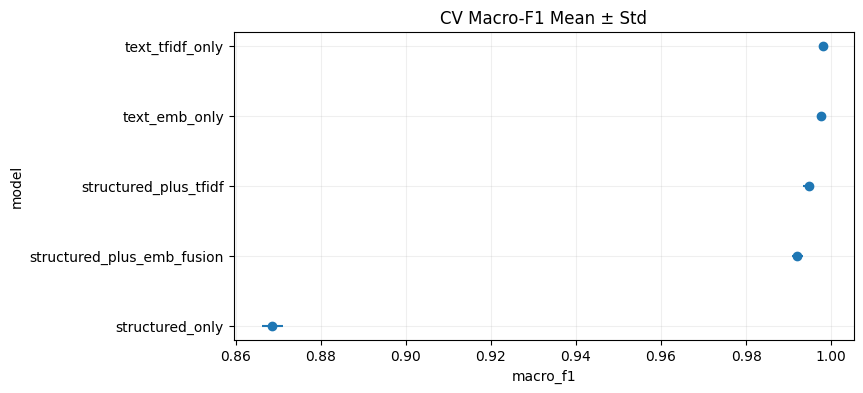

In [23]:
# CV stability summary (uses existing cv_summary; no retraining)
if 'cv_summary' not in globals():
    raise RuntimeError('cv_summary not found. Run the CV evaluation cell first.')

display_cols = [
    'model', 'folds',
    'macro_f1_mean', 'macro_f1_std',
    'accuracy_mean', 'accuracy_std',
    'undertriage_mean', 'severe_undertriage_mean', 'recall_esi_1_2_mean'
]

stable_df = cv_summary[display_cols].copy()
display(stable_df)

try:
    import matplotlib.pyplot as plt
    plot_df = stable_df.sort_values('macro_f1_mean', ascending=True)
    plt.figure(figsize=(8, 4))
    plt.errorbar(plot_df['macro_f1_mean'], plot_df['model'], xerr=plot_df['macro_f1_std'], fmt='o')
    plt.title('CV Macro-F1 Mean ± Std')
    plt.xlabel('macro_f1')
    plt.ylabel('model')
    plt.grid(alpha=0.2)
    plt.show()
except Exception:
    pass


## Model interpretability (cross-validated)

This section aggregates feature-importance signals across folds to reduce single-split bias.
It covers all trained model families in this notebook.


In [25]:
# Global feature importance aggregated across folds (all models)
if 'interp_df' not in globals() or interp_df.empty:
    raise RuntimeError('interp_df not found. Run the main CV training cell first.')

global_importance_summary = (
    interp_df
    .groupby(['model', 'feature'], as_index=False)
    .agg(
        importance_mean=('importance', 'mean'),
        importance_std=('importance', 'std'),
        fold_count=('fold', 'nunique'),
        best_rank=('rank', 'min'),
    )
)

for model_name in global_importance_summary['model'].unique():
    print(f"Top features for {model_name} (mean importance across folds)")
    display(
        global_importance_summary[global_importance_summary['model'] == model_name]
        .sort_values('importance_mean', ascending=False)
        .head(20)
    )



Top features for structured_only (mean importance across folds)


,model,feature,importance_mean,importance_std,fold_count,best_rank
129,structured_only,num__pain_score,23.874708,0.255622,5,1
124,structured_only,num__news2_score,17.351102,0.116424,5,2
95,structured_only,num__gcs_total,13.613714,0.283471,5,3
133,structured_only,num__spo2,8.626267,0.173078,5,4
135,structured_only,num__temperature_c,6.717920,0.112799,5,5
128,structured_only,num__num_prior_ed_visits_12m,5.647273,0.159842,5,6
131,structured_only,num__respiratory_rate,4.745299,0.172181,5,7
42,structured_only,cat__mental_status_triage_alert,4.063192,0.290694,5,8
96,structured_only,num__heart_rate,2.776565,0.131602,5,9
94,structured_only,num__diastolic_bp,2.639953,0.099588,5,9


Top features for structured_plus_emb_fusion (mean importance across folds)


,model,feature,importance_mean,importance_std,fold_count,best_rank
239,structured_plus_emb_fusion,num__news2_score,12.574844,0.562087,5,1
237,structured_plus_emb_fusion,num__gcs_total,6.917232,0.195874,5,2
241,structured_plus_emb_fusion,num__pain_score,6.048605,0.445227,5,3
243,structured_plus_emb_fusion,num__spo2,1.887210,0.046511,5,4
186,structured_plus_emb_fusion,emb::emb_191,1.579393,0.159699,5,4
240,structured_plus_emb_fusion,num__num_prior_ed_visits_12m,1.323128,0.120444,5,5
244,structured_plus_emb_fusion,num__temperature_c,1.271950,0.143262,5,6
216,structured_plus_emb_fusion,emb::emb_297,1.216004,0.059988,5,6
163,structured_plus_emb_fusion,emb::emb_099,1.194298,0.123186,5,6
197,structured_plus_emb_fusion,emb::emb_238,1.164205,0.121699,5,7


Top features for structured_plus_tfidf (mean importance across folds)


,model,feature,importance_mean,importance_std,fold_count,best_rank
285,structured_plus_tfidf,tfidf::mild,3.089761,0.031840,5,1
247,structured_plus_tfidf,num__gcs_total,2.629784,0.105952,5,2
293,structured_plus_tfidf,tfidf::moderate,2.292995,0.013078,5,3
253,structured_plus_tfidf,tfidf::advice,1.991299,0.003352,5,4
321,structured_plus_tfidf,tfidf::throat moderate,1.761743,0.013122,5,5
310,structured_plus_tfidf,tfidf::review,1.607478,0.015417,5,6
328,structured_plus_tfidf,tfidf::with,1.509175,0.047685,5,7
287,structured_plus_tfidf,tfidf::mild hypoglycaemia,1.488849,0.028271,5,7
252,structured_plus_tfidf,tfidf::acute,1.452094,0.055134,5,7
306,structured_plus_tfidf,tfidf::question,1.444286,0.008776,5,8


Top features for text_emb_only (mean importance across folds)


,model,feature,importance_mean,importance_std,fold_count,best_rank
361,text_emb_only,emb_099,778.6,39.163759,5,1
338,text_emb_only,emb_031,753.6,21.220273,5,1
399,text_emb_only,emb_245,711.8,14.822281,5,3
428,text_emb_only,emb_326,669.8,94.869384,5,1
381,text_emb_only,emb_191,667.6,21.858637,5,4
360,text_emb_only,emb_092,590.4,25.851499,5,5
354,text_emb_only,emb_070,582.4,23.028244,5,7
438,text_emb_only,emb_348,567.2,11.476062,5,8
417,text_emb_only,emb_297,564.8,26.032672,5,7
363,text_emb_only,emb_107,529.0,NaN,1,11


Top features for text_tfidf_only (mean importance across folds)


,model,feature,importance_mean,importance_std,fold_count,best_rank
484,text_tfidf_only,tfidf::mild,5.799613,0.071208,5,1
489,text_tfidf_only,tfidf::moderate,3.069504,0.096088,5,2
487,text_tfidf_only,tfidf::minor,2.963239,0.025306,5,2
450,text_tfidf_only,tfidf::advice,2.921164,0.029046,5,4
449,text_tfidf_only,tfidf::acute,2.895267,0.041734,5,4
502,text_tfidf_only,tfidf::severe,2.870987,0.034026,5,6
506,text_tfidf_only,tfidf::significant,2.435468,0.031566,5,7
511,text_tfidf_only,tfidf::suspected,2.301932,0.024434,5,8
500,text_tfidf_only,tfidf::review,2.201641,0.052223,5,9
529,text_tfidf_only,tfidf::with,2.195621,0.009922,5,9


In [26]:
# Block-level contribution (structured vs text) for mixed models
if 'interp_block_df' not in globals() or interp_block_df.empty:
    print('No block-level importance available.')
else:
    block_summary = (
        interp_block_df
        .groupby(['model', 'block'], as_index=False)
        .agg(
            share_mean=('share', 'mean'),
            share_std=('share', 'std'),
        )
    )
    display(block_summary.sort_values(['model', 'share_mean'], ascending=[True, False]))



,model,block,share_mean,share_std
1,structured_plus_emb_fusion,text_embedding,0.663479,0.006014
0,structured_plus_emb_fusion,structured,0.336521,0.006014
3,structured_plus_tfidf,text_tfidf,0.958440,0.000993
2,structured_plus_tfidf,structured,0.041560,0.000993


In [28]:
# Class-specific TF-IDF terms (most positive coefficients per class)
if 'tfidf_class_df' not in globals() or tfidf_class_df.empty:
    print('No TF-IDF class-term data available.')
else:
    tfidf_terms_summary = (
        tfidf_class_df
        .groupby(['model', 'class_label', 'term'], as_index=False)
        .agg(
            coef_mean=('coef', 'mean'),
            coef_std=('coef', 'std'),
            fold_count=('fold', 'nunique'),
            best_rank=('rank', 'min'),
        )
    )

    for class_label in sorted(tfidf_terms_summary['class_label'].unique()):
        print(f"Top TF-IDF terms for class {class_label}")
        display(
            tfidf_terms_summary[tfidf_terms_summary['class_label'] == class_label]
            .sort_values('coef_mean', ascending=False)
            .head(20)
        )



Top TF-IDF terms for class 1


,model,class_label,term,coef_mean,coef_std,fold_count,best_rank
13,text_tfidf_only,1,shock,4.795722,0.026268,5,1
7,text_tfidf_only,1,massive,4.745789,0.045920,5,2
18,text_tfidf_only,1,unresponsive,4.113164,0.063243,5,3
15,text_tfidf_only,1,syndrome,3.905878,0.053776,5,4
3,text_tfidf_only,1,arrest,3.491771,0.058390,5,5
8,text_tfidf_only,1,meningococcal,3.164075,0.060447,5,6
12,text_tfidf_only,1,severe hypothermia,3.158025,0.069330,5,6
19,text_tfidf_only,1,with haemorrhage,3.054271,0.089489,5,8
10,text_tfidf_only,1,penetrating,2.896398,0.042938,5,9
5,text_tfidf_only,1,fulminant,2.878159,0.051813,5,8


Top TF-IDF terms for class 2


,model,class_label,term,coef_mean,coef_std,fold_count,best_rank
23,text_tfidf_only,2,acute,6.271359,0.133284,5,1
38,text_tfidf_only,2,significant,6.008364,0.076261,5,2
36,text_tfidf_only,2,severe,5.555000,0.130474,5,3
43,text_tfidf_only,2,urosepsis,4.986826,0.083324,5,4
28,text_tfidf_only,2,hypothermia moderate,4.323429,0.056990,5,5
42,text_tfidf_only,2,torsion,3.766257,0.036432,5,6
24,text_tfidf_only,2,dka,3.640892,0.057405,5,7
25,text_tfidf_only,2,dka moderate,3.640892,0.057405,5,7
29,text_tfidf_only,2,meningitis,3.491647,0.031590,5,9
39,text_tfidf_only,2,suspected,3.430924,0.048964,5,10


Top TF-IDF terms for class 3


,model,class_label,term,coef_mean,coef_std,fold_count,best_rank
57,text_tfidf_only,3,moderate,7.673760,0.240221,5,1
63,text_tfidf_only,3,sinusitis severe,4.134644,0.023178,5,2
62,text_tfidf_only,3,sinusitis,4.134644,0.023178,5,2
56,text_tfidf_only,3,localised,4.094640,0.037346,5,2
65,text_tfidf_only,3,with,3.936961,0.051858,5,5
53,text_tfidf_only,3,haematuria,3.916269,0.027324,5,6
54,text_tfidf_only,3,haematuria significant,3.916269,0.027324,5,5
58,text_tfidf_only,3,new,3.836788,0.052589,5,7
67,text_tfidf_only,3,wound infection,3.565921,0.045169,5,9
64,text_tfidf_only,3,vitals,3.505860,0.029194,5,10


Top TF-IDF terms for class 4


,model,class_label,term,coef_mean,coef_std,fold_count,best_rank
79,text_tfidf_only,4,mild,7.978148,0.102906,5,1
88,text_tfidf_only,4,tonsillitis,5.088612,0.051826,5,2
70,text_tfidf_only,4,conjunctivitis,5.084676,0.034301,5,2
82,text_tfidf_only,4,moderate headache,5.071151,0.020339,5,2
74,text_tfidf_only,4,fatigue,5.003601,0.019331,5,5
86,text_tfidf_only,4,throat moderate,4.879636,0.051037,5,6
80,text_tfidf_only,4,mild hypoglycaemia,4.285192,0.061628,5,7
78,text_tfidf_only,4,insomnia severe,4.274881,0.014815,5,7
77,text_tfidf_only,4,insomnia,4.274881,0.014815,5,7
81,text_tfidf_only,4,minor,4.111593,0.070809,5,10


Top TF-IDF terms for class 5


,model,class_label,term,coef_mean,coef_std,fold_count,best_rank
91,text_tfidf_only,5,advice,7.302910,0.072614,5,1
96,text_tfidf_only,5,mild,6.520885,0.084152,5,2
110,text_tfidf_only,5,review,5.504102,0.130559,5,3
106,text_tfidf_only,5,question,5.136334,0.092352,5,4
108,text_tfidf_only,5,removal,4.972741,0.072062,5,5
109,text_tfidf_only,5,request,4.615148,0.076939,5,6
107,text_tfidf_only,5,referral,4.358154,0.045985,5,7
104,text_tfidf_only,5,prescription,4.279411,0.051416,5,8
105,text_tfidf_only,5,query,4.193927,0.075933,5,9
113,text_tfidf_only,5,throat irritation,3.874688,0.042004,5,10


In [29]:
# Optional local interpretability for fusion model (reference fold)
# Uses CatBoost SHAP values on a small sample to inspect local drivers.
RUN_LOCAL_SHAP = False

if RUN_LOCAL_SHAP:
    if 'fusion_model' not in globals() or 'x_va_emb' not in globals():
        raise RuntimeError('Missing reference fold artifacts. Run CV cell first.')

    try:
        # reference fold mixed matrix
        x_ref = np.hstack([x_va_struct, x_va_emb])
        shap_values = fusion_model.get_feature_importance(type='ShapValues', data=x_ref)
        # last column is expected value in CatBoost shap output
        shap_abs = np.abs(shap_values[:, :-1])

        # build names consistent with reference fold
        struct_names = [f'struct_{i}' for i in range(x_va_struct.shape[1])]
        emb_names = [f'emb::{i:03d}' for i in range(x_va_emb.shape[1])]
        feat_names = np.array(struct_names + emb_names)

        mean_abs = shap_abs.mean(axis=0)
        top_idx = np.argsort(mean_abs)[::-1][:20]
        local_shap_df = pd.DataFrame({
            'feature': feat_names[top_idx],
            'mean_abs_shap': mean_abs[top_idx],
        })
        display(local_shap_df)
    except Exception as exc:
        print('Local SHAP extraction failed:', exc)
else:
    print('Set RUN_LOCAL_SHAP=True to compute local CatBoost SHAP on reference fold.')



Set RUN_LOCAL_SHAP=True to compute local CatBoost SHAP on reference fold.


## CV stability and uncertainty
This section summarizes fold variability to show how stable each model is across splits.


- macro-F1: balance across classes (important if imbalanced).
  - undertriage/severe undertriage: safety-critical.
  - recall ESI 1-2: ability to catch urgent patients.

Safety-oriented metrics remain strong for text-based models in OOF evaluation, while structured-only undertriage is much higher.

Current OOF undertriage rates:
- `structured_only`: `0.0798`
- `text_tfidf_only`: `0.000638`
- `text_emb_only`: `0.000650`


Text-driven models are strongest in this dataset under OOF + 5-fold CV:
- `text_tfidf_only`: `macro_f1=0.9980`
- `text_emb_only`: `macro_f1=0.9977`
- `structured_only`: `macro_f1=0.8686`

Interpretation: chief complaint text carries a very strong acuity signal here.


Fusion (`structured_plus_emb_fusion`) is robust but does not beat text-only in this run (`macro_f1=0.9921` vs `0.9980` for TF-IDF text-only).

This is an important result: structured features add clinical context, but in this dataset they do not increase predictive performance over text alone.


In [30]:
# Confusion matrix (fusion, OOF)
y_true_int = to_int_labels(decode(oof['true_enc']))
y_pred_fusion_int = to_int_labels(decode(oof['pred_fusion']))
cm = pd.crosstab(
    pd.Series(y_true_int, name='true_acuity'),
    pd.Series(y_pred_fusion_int, name='pred_acuity'),
    dropna=False,
)
display(cm)


pred_acuity,1,2,3,4,5
true_acuity,,,,,
1,3088,134,0,0,0
2,2,13254,182,1,0
3,0,27,28883,6,5
4,0,0,17,23003,0
5,0,0,3,3,11392


In [31]:
#TODO:

# - Do this metric for all ?
# - shape f O.text
# - distribution of text concern gap -- they are really high , something is wrong
# - compare all acuity real/pred - where we fail more?
# - do UMAP i
 

## Complaint-structure mismatch

We define a Text Concern Gap using high-acuity probability mass (ESI 1-2):

`gap = P_text(ESI 1-2) - P_structured(ESI 1-2)`

Positive values indicate text model is more alarmed than structured-only model.

In [32]:
classes_int = np.asarray(label_encoder.classes_).astype(int)
high_mask = classes_int <= 2

p_high_text = oof['proba_text_emb'][:, high_mask].sum(axis=1)
p_high_struct = oof['proba_structured'][:, high_mask].sum(axis=1)
concern_gap = p_high_text - p_high_struct

mismatch_df = train_df[[id_col, text_col]].copy()
mismatch_df['true_acuity'] = y_true_int
mismatch_df['pred_structured'] = to_int_labels(decode(oof['pred_structured']))
mismatch_df['pred_text_emb'] = to_int_labels(decode(oof['pred_text_emb']))
mismatch_df['pred_fusion'] = y_pred_fusion_int
mismatch_df['p_high_text'] = p_high_text
mismatch_df['p_high_struct'] = p_high_struct
mismatch_df['text_concern_gap'] = concern_gap

gap_threshold = np.quantile(mismatch_df['text_concern_gap'], 0.90)
alert_cases = mismatch_df[mismatch_df['text_concern_gap'] >= gap_threshold].copy()

print('gap threshold (p90):', round(float(gap_threshold), 4))
print('alert case count:', len(alert_cases))
print('alert true high-acuity rate:', round((alert_cases['true_acuity'] <= 2).mean(), 4))

display(alert_cases.sort_values('text_concern_gap', ascending=False).head(20))


gap threshold (p90): 0.0018
alert case count: 8000
alert true high-acuity rate: 1.0


,patient_id,chief_complaint_raw,true_acuity,pred_structured,pred_text_emb,pred_fusion,p_high_text,p_high_struct,text_concern_gap
16114,TG-H5D40IEOV,"shoulder dislocation with vascular compromise,...",2,3,2,4,1.000000,0.002442,0.997558
16671,TG-GAX48L80C,"high-speed mva multiple injuries, since yesterday",2,3,2,3,1.000000,0.003499,0.996501
14118,TG-6I4EPWQ9R,acute severe psychosis with vomiting,2,3,2,3,1.000000,0.004306,0.995693
32246,TG-DPJENUJAK,"traumatic eye injury significant, constant",2,3,2,3,1.000000,0.005710,0.994290
63211,TG-T39H3JPWE,"eczema herpeticum, onset today",2,3,2,3,1.000000,0.006104,0.993896
73842,TG-PHILDEX0J,eczema herpeticum,2,3,2,3,1.000000,0.006532,0.993468
32519,TG-7LB0TXU91,acute mastoiditis with complications with diap...,2,3,2,3,0.999999,0.006916,0.993083
31333,TG-TVPIXY1M2,"severe dehydration, since yesterday",2,3,2,3,0.999999,0.006977,0.993022
73026,TG-T3ILTZKLL,"open fracture with contamination, worsening wi...",2,3,2,3,1.000000,0.009307,0.990693
15044,TG-EPA9ZIIRP,severe malaria with vomiting,2,3,2,3,0.999999,0.009543,0.990457


In [33]:
# Concern-gap diagnostics (uses existing mismatch_df; no retraining)
if 'mismatch_df' not in globals():
    raise RuntimeError('mismatch_df not found. Run the mismatch cell first.')

q = mismatch_df['text_concern_gap'].quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0])
print('Concern-gap quantiles:')
display(q.to_frame('text_concern_gap'))

mismatch_df['is_high_acuity'] = (mismatch_df['true_acuity'] <= 2).astype(int)
summary_gap = mismatch_df.groupby('is_high_acuity')['text_concern_gap'].describe()[['mean', 'std', '50%', '90%']]
print('Gap by high-acuity (0=no, 1=yes):')
display(summary_gap)

try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(7, 3.5))
    mismatch_df['text_concern_gap'].hist(bins=80)
    plt.title('Distribution of Text Concern Gap')
    plt.xlabel('text_concern_gap')
    plt.ylabel('count')
    plt.show()
except Exception:
    pass


Concern-gap quantiles:


,text_concern_gap
0.00,-0.971011
0.10,-0.005800
0.25,-0.000655
0.50,-0.000103
0.75,-0.000021
0.90,0.001760
0.99,0.136546
1.00,0.997558


KeyError: "['90%'] not in index"

Top text-concern-gap cases are strongly enriched for high acuity in this run.

Current OOF mismatch summary:
- gap threshold (p90): `0.0018`
- alert case count: `8000`
- high-acuity rate in alerts: `1.0`


Complaint clustering
- What it does:
  - clusters embedding vectors,
  - shows cluster-level high-acuity rates and sample complaints.
- Why it matters:
  - gives interpretable clinical themes.
- What to look for:
  - clusters with high acuity prevalence,
  - clusters with high concern-gap means.

In [34]:
#TODO:

# - do UMAP to visualize clusters
### Ines -> i need to run things before (bahhhh)

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Con

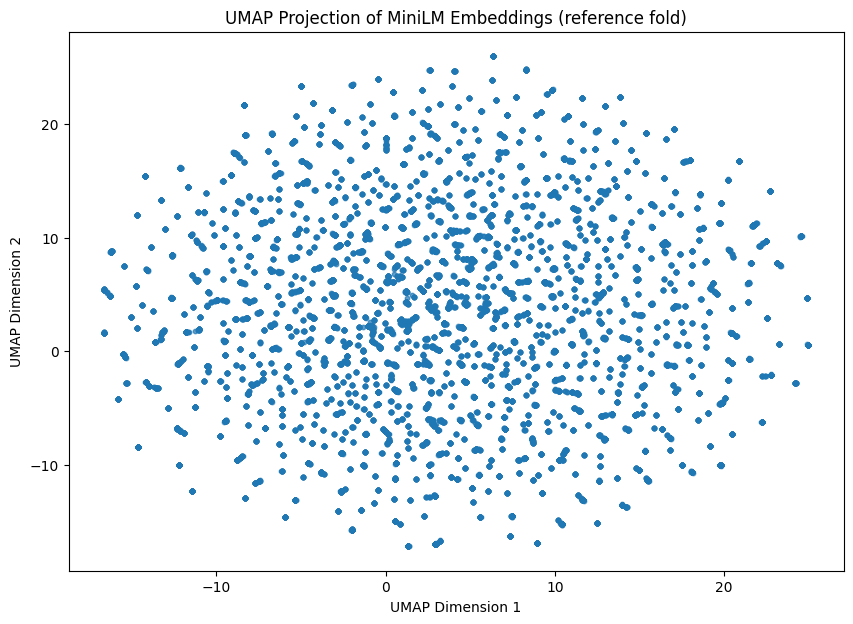

In [35]:
try:
    import umap
    import matplotlib.pyplot as plt
except Exception as exc:
    raise ImportError("Install umap-learn to run this visualization: pip install umap-learn") from exc

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42
)
embedding = reducer.fit_transform(x_va_emb)

# Plot the 2D embedding
plt.figure(figsize=(10, 7))
plt.scatter(embedding[:, 0], embedding[:, 1], s=10, alpha=0.7)
plt.title("UMAP Projection of MiniLM Embeddings (reference fold)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.show()


In [36]:
# Complaint clustering and interpretation (reference fold)
y_true_ref_int = to_int_labels(decode(y_va))
concern_gap_ref = (
    ref_artifacts['proba_emb_text'][:, high_mask].sum(axis=1)
    - ref_artifacts['proba_struct'][:, high_mask].sum(axis=1)
)

n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=10)
cluster_id = kmeans.fit_predict(x_va_emb)

cluster_df = va[[text_col]].copy()
cluster_df['cluster'] = cluster_id
cluster_df['true_acuity'] = y_true_ref_int
cluster_df['text_concern_gap'] = concern_gap_ref

cluster_summary = cluster_df.groupby('cluster').agg(
    n=('cluster', 'size'),
    high_acuity_rate=('true_acuity', lambda s: np.mean(s <= 2)),
    mean_text_concern_gap=('text_concern_gap', 'mean'),
).sort_values('high_acuity_rate', ascending=False)
display(cluster_summary)

# Representative complaints: first few examples per cluster
examples = (
    cluster_df.groupby('cluster')[text_col]
    .apply(lambda s: list(s.head(5)))
    .to_frame('sample_complaints')
)
display(examples)

cluster_esi = pd.crosstab(cluster_df['cluster'], cluster_df['true_acuity'], normalize='index')
display(cluster_esi)


,n,high_acuity_rate,mean_text_concern_gap
cluster,,,
5,1129,0.433127,0.003608
0,2879,0.300104,0.005769
2,1455,0.237113,0.007860
7,2354,0.209431,-0.001862
1,1514,0.174373,-0.004143
4,1504,0.144282,-0.001303
6,2375,0.128842,-0.001063
3,2790,0.126882,-0.002276


,sample_complaints
cluster,
0,"[coma of unknown cause, for 2 days, hyperglyca..."
1,"[inhaler technique question with fever, mild c..."
2,[appendicitis clinically suspected with diapho...
3,"[acute altered mental status, worsening with m..."
4,[community pneumonia moderate in known patient...
5,"[stab wound abdomen stable, since yesterday, l..."
6,"[new facial droop resolved, constant, rapidly ..."
7,[obstruction with bilious vomiting in known pa...


true_acuity,1,2,3,4,5
cluster,,,,,
0,0.058006,0.242098,0.251129,0.203543,0.245224
1,0.027741,0.146631,0.449141,0.268824,0.107662
2,0.032302,0.204811,0.358763,0.291409,0.112715
3,0.026882,0.100000,0.395341,0.360932,0.116846
4,0.030585,0.113697,0.378324,0.327128,0.150266
5,0.116918,0.316209,0.391497,0.147919,0.027458
6,0.019789,0.109053,0.379789,0.352421,0.138947
7,0.037383,0.172048,0.358114,0.290569,0.141886


In [37]:
#TODO:

# - see for each model the probabilities of what se fail and what we get right / boxplot with false negatives /positives

 Review-flag logic
- What it does:
  - flags cases with low fusion confidence or high concern gap.
- Why it matters:
  - converts model output into actionable triage support behavior.
- What to look for:
  - flagged set should be enriched for difficult/high-risk cases, not random.


In [38]:
# Review-flag logic (support tool, not auto-overrule)
pmax_fusion = oof['proba_fusion'].max(axis=1)
low_conf_threshold = np.quantile(pmax_fusion, 0.10)
high_gap_threshold = np.quantile(concern_gap, 0.90)

mismatch_df['fusion_confidence'] = pmax_fusion
mismatch_df['review_flag'] = (
    (mismatch_df['fusion_confidence'] <= low_conf_threshold)
    | (mismatch_df['text_concern_gap'] >= high_gap_threshold)
)

flagged = mismatch_df[mismatch_df['review_flag']]
print('review flag rate:', round(len(flagged) / len(mismatch_df), 4))
print('high-acuity rate among flagged:', round((flagged['true_acuity'] <= 2).mean(), 4))
display(flagged.head(20))


review flag rate: 0.1912
high-acuity rate among flagged: 0.5779


,patient_id,chief_complaint_raw,true_acuity,pred_structured,pred_text_emb,pred_fusion,p_high_text,p_high_struct,text_concern_gap,is_high_acuity,fusion_confidence,review_flag
0,TG-UXRGA9UCO,"thunderclap headache, worsening with movement",2,2,2,2,9.999991e-01,0.981062,0.018937,1,0.993504,True
2,TG-GZ97W7M6V,"general health question, intermittent",5,5,5,5,6.000026e-08,0.000177,-0.000177,0,0.685543,True
5,TG-1UXV144MT,shingles with pain with associated nausea,3,4,3,3,1.821636e-07,0.000221,-0.000221,0,0.890184,True
7,TG-WFM0W3TUS,substance intoxication，worsening over hours,3,3,3,3,5.006032e-08,0.000556,-0.000556,0,0.859816,True
8,TG-NMIVSUYHH,"small cut wound check, intermittent",5,4,5,5,8.007081e-08,0.000077,-0.000077,0,0.767302,True
9,TG-FPU1JAUHF,minor facial laceration with rigors,4,4,4,4,1.040612e-07,0.000269,-0.000268,0,0.886460,True
12,TG-2YVI5MZSN,sudden loss of vision with associated nausea,2,2,2,2,9.999989e-01,0.893536,0.106463,1,0.856174,True
17,TG-BOVZKJL6Q,chronic headache review with diaphoresis,5,5,5,5,4.390084e-08,0.000023,-0.000023,0,0.854410,True
21,TG-N1A4TQLMJ,viral urti mild with diaphoresis,5,4,5,5,6.855256e-08,0.000091,-0.000091,0,0.887505,True
28,TG-YFF1W7DB1,stab wound abdomen stable in known patient,2,2,2,2,9.999996e-01,0.979375,0.020624,1,0.936560,True


Current OOF review-flag behavior:
- review flag rate: `0.1912`
- high-acuity rate among flagged: `0.5779`

Interpretation: the review flag captures a smaller subset enriched for urgent cases, supporting triage-assist workflow use.


In [39]:
# Robustness quick checks: typo and truncation perturbations
def perturb_typo(s: str) -> str:
    t = '' if s is None else str(s)
    if len(t) < 5:
        return t
    return t[:-1] + 'x'


def perturb_short(s: str) -> str:
    t = '' if s is None else str(s)
    return ' '.join(t.split()[:2])

rob_n = min(2000, len(va))
rob_text = va[text_col].head(rob_n).tolist()
rob_typo = [perturb_typo(x) for x in rob_text]
rob_short = [perturb_short(x) for x in rob_text]

rob_emb = encode_complaints(rob_text, model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)
rob_typo_emb = encode_complaints(rob_typo, model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)
rob_short_emb = encode_complaints(rob_short, model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)

rob_struct = x_va_struct[:rob_n]
pred_base = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_emb]))).reshape(-1).astype(int)
pred_typo = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_typo_emb]))).reshape(-1).astype(int)
pred_short = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_short_emb]))).reshape(-1).astype(int)

print('stability vs typo perturbation:', round(float(np.mean(pred_base == pred_typo)), 4))
print('stability vs shortened complaint:', round(float(np.mean(pred_base == pred_short)), 4))


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7540.29it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13163.11it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 15875.84it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embe

stability vs typo perturbation: 0.964
stability vs shortened complaint: 0.9365


Robustness remains acceptable in this run:
- stability vs typo perturbation: `0.964`
- stability vs shortened complaint: `0.9365`

This suggests embedding-based predictions are reasonably stable to minor complaint text noise.


In [40]:
# Fairness / subgroup snapshot on OOF fusion predictions
subgroups = [c for c in ['age_group', 'sex', 'site_id'] if c in train_df.columns]
subgroup_rows = []
for col in subgroups:
    temp = train_df[[col]].copy()
    temp['y_true'] = y_true_int
    temp['y_pred'] = y_pred_fusion_int
    for grp, gdf in temp.groupby(col):
        if len(gdf) < 50:
            continue
        subgroup_rows.append({
            'group_col': col,
            'group_val': grp,
            'n': len(gdf),
            'accuracy': float(np.mean(gdf['y_true'] == gdf['y_pred'])),
            'undertriage_rate': float(np.mean(gdf['y_pred'] > gdf['y_true'])),
        })
subgroup_df = pd.DataFrame(subgroup_rows).sort_values(['group_col', 'n'], ascending=[True, False])
display(subgroup_df.head(30))


,group_col,group_val,n,accuracy,undertriage_rate
1,age_group,middle_aged,27889,0.996235,0.003371
3,age_group,young_adult,23863,0.994846,0.004107
0,age_group,elderly,21653,0.994273,0.005172
2,age_group,pediatric,6595,0.995754,0.003639
4,sex,F,40339,0.994893,0.004413
5,sex,M,37735,0.995601,0.003763
6,sex,Other,1926,0.995846,0.004154
11,site_id,SITE-TUR-01,16212,0.995004,0.004503
7,site_id,SITE-HEL-01,16161,0.994864,0.004146
8,site_id,SITE-HEL-02,15912,0.996041,0.003582


Subgroup snapshot is fairly consistent, with modest variation across age/sex/site.

Observed undertriage ranges in this run:
- age groups: about `0.0034` to `0.0052`
- sex: about `0.0038` to `0.0044`
- sites: about `0.0036` to `0.0046`


## What still needs to be checked to solidify the project

### High priority (before final claims)
- [ ] Run `CV_MODE='group_site'` and compare with stratified CV to test site transferability.
- [ ] Add per-class recall/precision/F1 table (focus on ESI 1-2 and severe misses).
- [ ] Validate undertriage direction assumptions explicitly (ESI 1 most urgent -> undertriage when `pred > true`).
- [ ] Re-check leakage guardrails: ensure no post-triage fields enter any model path.

### Model reliability checks
- [ ] Plot confidence for correct vs incorrect predictions and for undertriage vs non-undertriage cases.
- [ ] Add calibration check (reliability curve or binned confidence) for fusion model.
- [ ] Confirm robustness under complaint perturbations on a larger sample (not only 2k).

### Text shortcut and generalization checks
- [ ] Audit complaint overlap/near-duplicates across folds (possible shortcut risk).
- [ ] Report complaint-frequency dependence (performance for rare vs common complaint text).
- [ ] Compare with a shuffled-text negative control to verify true language signal.

### Clinical interpretation and reporting
- [ ] Replace all static result claims with run-derived values from current OOF/CV outputs.
- [ ] Add 5-10 representative mismatch cases with clinical interpretation.
- [ ] Finalize review-flag operating point (threshold rationale + flag workload).


In [41]:
# Shortcut-risk quick diagnostics (no retraining)
# 1) Complaint duplication ratio
complaint_counts = train_df[text_col].astype(str).value_counts()
dup_ratio = float((complaint_counts > 1).mean())
print('Unique complaint strings:', complaint_counts.shape[0])
print('Share of complaint strings appearing >1 time:', round(dup_ratio, 4))

# 2) Top complaints and acuity purity
top_n = 20
top_complaints = complaint_counts.head(top_n).index
purity_rows = []
for txt in top_complaints:
    sub = train_df[train_df[text_col].astype(str) == txt]
    mode_rate = sub[target_col].value_counts(normalize=True).iloc[0]
    purity_rows.append({'complaint': txt, 'n': len(sub), 'majority_acuity_share': float(mode_rate)})

purity_df = pd.DataFrame(purity_rows).sort_values('majority_acuity_share', ascending=False)
display(purity_df.head(10))


Unique complaint strings: 4949
Share of complaint strings appearing >1 time: 0.9705


,complaint,n,majority_acuity_share
0,sti with systemic features in known patient,44,1.0
1,new-onset jaundice with vomiting,43,1.0
18,"eyelid swelling, worsening with movement",39,1.0
17,"sinusitis severe, no prior history of this",39,1.0
16,fall with injury unclear with fever,39,1.0
15,"allergic rash moderate, intermittent",39,1.0
14,"new facial droop resolved, constant",39,1.0
13,wound infection localised with associated nausea,40,1.0
12,"cellulitis localised, worsening with movement",40,1.0
11,"transient limb weakness, no prior history of this",40,1.0


### Extra verification cells (optional but recommended)
The cells below implement checks from the checklist. They use existing OOF outputs where possible, so they do **not** require rerunning the full CV unless you explicitly enable the optional heavy checks.


In [42]:
# 1) Undertriage direction sanity + per-class diagnostics (OOF, no retraining)
if 'oof' not in globals():
    raise RuntimeError('oof not found. Run CV training/evaluation cells first.')

# Direction sanity check: ESI 1 most urgent, ESI 5 least urgent
# Undertriage should be pred > true
y_true_int = decode(oof['true_enc']).astype(int)
y_pred_fusion_int = decode(oof['pred_fusion']).astype(int)
print('Direction sanity: undertriage = pred > true')
print('Undertriage rate (fusion OOF):', round(float((y_pred_fusion_int > y_true_int).mean()), 6))
print('Overtriage rate (fusion OOF):', round(float((y_pred_fusion_int < y_true_int).mean()), 6))

models_for_class = {
    'structured_only': oof['pred_structured'],
    'text_tfidf_only': oof['pred_text_tfidf'],
    'structured_plus_tfidf': oof['pred_structured_tfidf'],
    'text_emb_only': oof['pred_text_emb'],
    'structured_plus_emb_fusion': oof['pred_fusion'],
}

class_rows = []
classes = sorted(np.unique(y_true_int))
for model_name, pred_enc in models_for_class.items():
    pred_int = decode(pred_enc).astype(int)
    for c in classes:
        mask = (y_true_int == c)
        if mask.sum() == 0:
            continue
        recall_c = (pred_int[mask] == c).mean()
        # precision for class c
        pred_mask = (pred_int == c)
        precision_c = ((y_true_int[pred_mask] == c).mean() if pred_mask.sum() > 0 else np.nan)
        class_rows.append({
            'model': model_name,
            'acuity_class': c,
            'n_true': int(mask.sum()),
            'recall': float(recall_c),
            'precision': float(precision_c),
        })

per_class_df = pd.DataFrame(class_rows)
display(per_class_df.sort_values(['model','acuity_class']))

# High-acuity focused summary (ESI 1-2)
high_rows = []
for model_name, pred_enc in models_for_class.items():
    pred_int = decode(pred_enc).astype(int)
    high_mask_local = y_true_int <= 2
    high_rows.append({
        'model': model_name,
        'recall_esi_1_2': float((pred_int[high_mask_local] <= 2).mean()),
        'undertriage_within_esi_1_2': float((pred_int[high_mask_local] > y_true_int[high_mask_local]).mean()),
    })

display(pd.DataFrame(high_rows).sort_values('recall_esi_1_2', ascending=False))


Direction sanity: undertriage = pred > true
Undertriage rate (fusion OOF): 0.0041
Overtriage rate (fusion OOF): 0.00065


,model,acuity_class,n_true,recall,precision
0,structured_only,1,3222,0.908752,0.976000
1,structured_only,2,13439,0.968748,0.966231
2,structured_only,3,28921,0.883925,0.892785
3,structured_only,4,23020,0.772546,0.763393
4,structured_only,5,11398,0.785050,0.771645
20,structured_plus_emb_fusion,1,3222,0.958411,0.999353
21,structured_plus_emb_fusion,2,13439,0.986234,0.987999
22,structured_plus_emb_fusion,3,28921,0.998686,0.993055
23,structured_plus_emb_fusion,4,23020,0.999262,0.999565
24,structured_plus_emb_fusion,5,11398,0.999474,0.999561


,model,recall_esi_1_2,undertriage_within_esi_1_2
1,text_tfidf_only,1.000000,0.003061
3,text_emb_only,1.000000,0.003121
2,structured_plus_tfidf,0.996639,0.008523
4,structured_plus_emb_fusion,0.989016,0.019026
0,structured_only,0.979113,0.038533


In [43]:
# 2) Confidence-vs-error diagnostics (OOF fusion, no retraining)
if 'oof' not in globals():
    raise RuntimeError('oof not found. Run CV training/evaluation cells first.')

conf = oof['proba_fusion'].max(axis=1)
correct = (oof['pred_fusion'] == oof['true_enc'])
y_true_int = decode(oof['true_enc']).astype(int)
y_pred_int = decode(oof['pred_fusion']).astype(int)
under = y_pred_int > y_true_int

diag_df = pd.DataFrame({
    'confidence': conf,
    'correct': correct,
    'undertriage': under,
    'true_acuity': y_true_int,
    'pred_acuity': y_pred_int,
})

summary = pd.DataFrame({
    'group': ['correct','incorrect','undertriage','not_undertriage'],
    'mean_confidence': [
        diag_df.loc[diag_df['correct'], 'confidence'].mean(),
        diag_df.loc[~diag_df['correct'], 'confidence'].mean(),
        diag_df.loc[diag_df['undertriage'], 'confidence'].mean(),
        diag_df.loc[~diag_df['undertriage'], 'confidence'].mean(),
    ]
})
display(summary)

# Confidence bins vs error rate
bins = np.linspace(0.0, 1.0, 11)
diag_df['conf_bin'] = pd.cut(diag_df['confidence'], bins=bins, include_lowest=True)
err_by_bin = diag_df.groupby('conf_bin', observed=False).agg(
    n=('confidence','size'),
    error_rate=('correct', lambda s: 1 - s.mean()),
    undertriage_rate=('undertriage','mean'),
)
display(err_by_bin)


,group,mean_confidence
0,correct,0.957537
1,incorrect,0.650447
2,undertriage,0.661973
3,not_undertriage,0.957289


,n,error_rate,undertriage_rate
conf_bin,,,
"(-0.001, 0.1]",0,NaN,NaN
"(0.1, 0.2]",0,NaN,NaN
"(0.2, 0.3]",0,NaN,NaN
"(0.3, 0.4]",0,NaN,NaN
"(0.4, 0.5]",46,0.369565,0.239130
"(0.5, 0.6]",412,0.332524,0.262136
"(0.6, 0.7]",721,0.141470,0.122053
"(0.7, 0.8]",1510,0.050993,0.049007
"(0.8, 0.9]",5591,0.006439,0.006439


In [44]:
# 3) Calibration-style check for high-acuity risk (OOF fusion, no retraining)
# Event: high acuity (ESI 1-2)
if 'oof' not in globals():
    raise RuntimeError('oof not found. Run CV training/evaluation cells first.')

classes_int = np.asarray(label_encoder.classes_).astype(int)
high_mask = classes_int <= 2
p_high_fusion = oof['proba_fusion'][:, high_mask].sum(axis=1)
y_high_true = (decode(oof['true_enc']).astype(int) <= 2).astype(int)

cal_df = pd.DataFrame({'p_high': p_high_fusion, 'y_high': y_high_true})
cal_df['bin'] = pd.qcut(cal_df['p_high'], q=10, duplicates='drop')
cal_summary = cal_df.groupby('bin', observed=False).agg(
    n=('p_high','size'),
    mean_pred=('p_high','mean'),
    obs_rate=('y_high','mean'),
)
cal_summary['calibration_gap'] = cal_summary['mean_pred'] - cal_summary['obs_rate']
display(cal_summary)


,n,mean_pred,obs_rate,calibration_gap
bin,,,,
"(-0.00099203, 0.000227]",8000,0.000145,0.000000,0.000145
"(0.000227, 0.000383]",8000,0.000303,0.000000,0.000303
"(0.000383, 0.000589]",8000,0.000480,0.000000,0.000480
"(0.000589, 0.000931]",8000,0.000744,0.000000,0.000744
"(0.000931, 0.00159]",8000,0.001223,0.000000,0.001223
"(0.00159, 0.00292]",8000,0.002155,0.000000,0.002155
"(0.00292, 0.00664]",8000,0.004403,0.000000,0.004403
"(0.00664, 0.913]",8000,0.079834,0.082625,-0.002791
"(0.913, 0.998]",8000,0.991046,1.000000,-0.008954


In [45]:
# 4) Rare-vs-common complaint performance (OOF fusion, no retraining)
if 'oof' not in globals():
    raise RuntimeError('oof not found. Run CV training/evaluation cells first.')

freq = train_df[text_col].astype(str).value_counts()
row_freq = train_df[text_col].astype(str).map(freq)

y_true_int = decode(oof['true_enc']).astype(int)
y_pred_int = decode(oof['pred_fusion']).astype(int)

freq_df = pd.DataFrame({
    'complaint_freq': row_freq.values,
    'correct': (oof['pred_fusion'] == oof['true_enc']).astype(int),
    'undertriage': (y_pred_int > y_true_int).astype(int),
})

freq_df['freq_band'] = pd.cut(
    freq_df['complaint_freq'],
    bins=[0, 1, 2, 5, 10, 20, np.inf],
    labels=['1', '2', '3-5', '6-10', '11-20', '20+'],
    include_lowest=True,
)

band_summary = freq_df.groupby('freq_band', observed=False).agg(
    n=('correct','size'),
    accuracy=('correct','mean'),
    undertriage_rate=('undertriage','mean'),
)
display(band_summary)


,n,accuracy,undertriage_rate
freq_band,,,
1,146,0.958904,0.041096
2,436,0.956422,0.043578
3-5,2009,0.963664,0.036336
6-10,4580,0.986245,0.012664
11-20,28461,0.994132,0.005446
20+,44368,0.998828,0.000383


In [46]:
# 5) Optional heavy check: Group-site CV for selected models
RUN_GROUP_SITE_CHECK = False  # set True to execute (will retrain models)

if RUN_GROUP_SITE_CHECK:
    if 'site_id' not in train_df.columns:
        raise RuntimeError('site_id not found; cannot run group-site CV check.')

    g_splits = list(GroupKFold(n_splits=N_SPLITS).split(train_df, y_all, groups=train_df['site_id']))
    rows_group = []

    for fold, (tr_idx, va_idx) in enumerate(g_splits, start=1):
        tr_fold = train_df.iloc[tr_idx].reset_index(drop=True)
        va_fold = train_df.iloc[va_idx].reset_index(drop=True)
        y_tr_fold = y_all[tr_idx]
        y_va_fold = y_all[va_idx]

        struct_cols = infer_structured_columns(
            tr_fold,
            target_col=target_col,
            text_col=text_col,
            id_col=id_col,
            explicit_drop_cols=leakage_cols,
        )
        _, x_tr_struct, x_va_struct = fit_transform_structured(tr_fold[struct_cols], va_fold[struct_cols])

        # Structured-only
        model_struct = make_classifier('catboost', {'iterations': 300, 'depth': 6, 'learning_rate': 0.05, 'verbose': False}, n_classes=len(label_encoder.classes_))
        model_struct.fit(x_tr_struct, y_tr_fold)
        pred_struct = np.asarray(model_struct.predict(x_va_struct)).reshape(-1).astype(int)

        # Text-only TF-IDF
        _, x_tr_tfidf, x_va_tfidf = fit_transform_tfidf(tr_fold[text_col], va_fold[text_col], max_features=25000, ngram_range=(1,2))
        model_tfidf = LogisticRegression(max_iter=1200, solver='lbfgs')
        model_tfidf.fit(x_tr_tfidf, y_tr_fold)
        pred_tfidf = model_tfidf.predict(x_va_tfidf).astype(int)

        # Fusion MiniLM
        x_tr_emb = encode_complaints(tr_fold[text_col], model_name=emb_model_name, batch_size=emb_batch_size)
        x_va_emb = encode_complaints(va_fold[text_col], model_name=emb_model_name, batch_size=emb_batch_size)
        model_fusion = make_classifier('catboost', {'iterations': 350, 'depth': 6, 'learning_rate': 0.05, 'verbose': False}, n_classes=len(label_encoder.classes_))
        model_fusion.fit(np.hstack([x_tr_struct, x_tr_emb]), y_tr_fold)
        pred_fusion = np.asarray(model_fusion.predict(np.hstack([x_va_struct, x_va_emb]))).reshape(-1).astype(int)

        for m, p in [('structured_only', pred_struct), ('text_tfidf_only', pred_tfidf), ('structured_plus_emb_fusion', pred_fusion)]:
            r = eval_esi(y_va_fold, p)
            rows_group.append({'fold': fold, 'model': m, **r})

    group_cv = pd.DataFrame(rows_group).groupby('model', as_index=False).agg(
        folds=('fold','count'),
        macro_f1_mean=('macro_f1','mean'),
        undertriage_mean=('undertriage_rate','mean'),
        recall_esi_1_2_mean=('recall_esi_1_2','mean'),
    ).sort_values('macro_f1_mean', ascending=False)

    print('Group-site CV summary:')
    display(group_cv)
else:
    print('Set RUN_GROUP_SITE_CHECK=True to run group-site CV comparison.')


Set RUN_GROUP_SITE_CHECK=True to run group-site CV comparison.


In [47]:
# 6) Optional heavy check: shuffled-text negative control
RUN_SHUFFLE_TEXT_CONTROL = False  # set True to execute (trains a control model)

if RUN_SHUFFLE_TEXT_CONTROL:
    rng = np.random.default_rng(SEED)

    # Use first CV fold for a fast control
    tr_idx, va_idx = splits[0]
    tr_fold = train_df.iloc[tr_idx].reset_index(drop=True)
    va_fold = train_df.iloc[va_idx].reset_index(drop=True)
    y_tr_fold = y_all[tr_idx]
    y_va_fold = y_all[va_idx]

    shuffled_text = tr_fold[text_col].sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    _, x_tr_tfidf_shuf, x_va_tfidf = fit_transform_tfidf(shuffled_text, va_fold[text_col], max_features=25000, ngram_range=(1,2))

    model_ctrl = LogisticRegression(max_iter=1200, solver='lbfgs')
    model_ctrl.fit(x_tr_tfidf_shuf, y_tr_fold)
    pred_ctrl = model_ctrl.predict(x_va_tfidf).astype(int)

    ctrl_metrics = eval_esi(y_va_fold, pred_ctrl)
    print('Shuffled-text control metrics (single fold):')
    print(ctrl_metrics)
else:
    print('Set RUN_SHUFFLE_TEXT_CONTROL=True to run shuffled-text negative control.')


Set RUN_SHUFFLE_TEXT_CONTROL=True to run shuffled-text negative control.


## Export final submission

We train fusion on full training data, predict test acuity, and write a Kaggle-ready CSV.

In [ ]:
# Refit with CV fold ensemble for submission
SELECTED_MODEL = 'structured_plus_emb_fusion'  # choose from compared models

splits_sub = make_splitter(train_df, y_all, mode=CV_MODE, n_splits=N_SPLITS, seed=SEED)
proba_test_accum = np.zeros((len(test_df), len(label_encoder.classes_)), dtype=float)

for fold, (tr_idx, va_idx) in enumerate(splits_sub, start=1):
    tr_fold = train_df.iloc[tr_idx].reset_index(drop=True)
    y_tr_fold = y_all[tr_idx]

    struct_cols_fold = infer_structured_columns(
        tr_fold,
        target_col=target_col,
        text_col=text_col,
        id_col=id_col,
        explicit_drop_cols=leakage_cols,
    )
    struct_pre_fold, x_tr_struct_fold, x_test_struct_fold = fit_transform_structured(
        tr_fold[struct_cols_fold], test_df[struct_cols_fold]
    )

    if SELECTED_MODEL == 'structured_only':
        model = make_classifier('catboost', {'iterations': 350, 'depth': 6, 'learning_rate': 0.05, 'verbose': False}, n_classes=len(label_encoder.classes_))
        model.fit(x_tr_struct_fold, y_tr_fold)
        proba_test_fold = np.asarray(model.predict_proba(x_test_struct_fold))

    elif SELECTED_MODEL == 'text_tfidf_only':
        _, x_tr_tfidf_fold, x_test_tfidf = fit_transform_tfidf(tr_fold[text_col], test_df[text_col], max_features=25000, ngram_range=(1, 2))
        model = LogisticRegression(max_iter=1200, solver='lbfgs')
        model.fit(x_tr_tfidf_fold, y_tr_fold)
        proba_test_fold = np.asarray(model.predict_proba(x_test_tfidf))

    elif SELECTED_MODEL == 'structured_plus_tfidf':
        _, x_tr_tfidf_fold, x_test_tfidf = fit_transform_tfidf(tr_fold[text_col], test_df[text_col], max_features=25000, ngram_range=(1, 2))
        x_tr_mix = hstack([csr_matrix(x_tr_struct_fold), x_tr_tfidf_fold]).tocsr()
        x_test_mix = hstack([csr_matrix(x_test_struct_fold), x_test_tfidf]).tocsr()
        model = LogisticRegression(max_iter=1200, solver='lbfgs')
        model.fit(x_tr_mix, y_tr_fold)
        proba_test_fold = np.asarray(model.predict_proba(x_test_mix))

    elif SELECTED_MODEL == 'text_emb_only':
        x_tr_emb_fold = encode_complaints(tr_fold[text_col], model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)
        x_test_emb = encode_complaints(test_df[text_col], model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)
        model = make_classifier('lightgbm', {'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 63}, n_classes=len(label_encoder.classes_))
        model.fit(x_tr_emb_fold, y_tr_fold)
        proba_test_fold = np.asarray(model.predict_proba(x_test_emb))

    elif SELECTED_MODEL == 'structured_plus_emb_fusion':
        x_tr_emb_fold = encode_complaints(tr_fold[text_col], model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)
        x_test_emb = encode_complaints(test_df[text_col], model_name=emb_model_name, batch_size=emb_batch_size, backend=emb_backend)
        x_tr_mix = np.hstack([x_tr_struct_fold, x_tr_emb_fold])
        x_test_mix = np.hstack([x_test_struct_fold, x_test_emb])
        model = make_classifier('catboost', {'iterations': 450, 'depth': 6, 'learning_rate': 0.05, 'verbose': False}, n_classes=len(label_encoder.classes_))
        model.fit(x_tr_mix, y_tr_fold)
        proba_test_fold = np.asarray(model.predict_proba(x_test_mix))

    else:
        raise ValueError(f'Unsupported SELECTED_MODEL: {SELECTED_MODEL}')

    proba_test_accum += proba_test_fold
    print(f'Submission fold {fold}/{len(splits_sub)} done')

proba_test_mean = proba_test_accum / len(splits_sub)
test_pred_enc = proba_test_mean.argmax(axis=1)
test_pred = label_encoder.inverse_transform(test_pred_enc).astype(int)

submission = pd.DataFrame({id_col: test_df[id_col], target_col: test_pred})

out_dir = PROJECT_ROOT / 'outputs'
out_dir.mkdir(parents=True, exist_ok=True)
submission_path = out_dir / 'submission_notebook_cv.csv'
submission.to_csv(submission_path, index=False)
print('saved:', submission_path)
display(submission.head())


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13264.96it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8566.08it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Submission fold 1/5 done


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8155.81it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8094.99it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Submission fold 2/5 done


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8716.98it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6984.52it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Submission fold 3/5 done


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9199.01it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7484.38it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Submission fold 4/5 done


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8356.48it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6474.34it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Submission fold 5/5 done
saved: /Users/raquel_romao/Documents/3AIG_TriageKeggleCompetition/3AIG/outputs/submission_notebook_cv.csv


,patient_id,triage_acuity
0,TG-FZUFCRZS3,2
1,TG-SSCOXTYI1,3
2,TG-JY74ZR35D,2
3,TG-JDKD5G62X,4
4,TG-J1BSAAXR0,4


## Deployment concept (triage support, not replacement)

1. Nurse enters structured triage intake and chief complaint text.
2. System outputs acuity suggestion with confidence and concern-gap signal.
3. Large text-vs-structure disagreement or low confidence triggers a review flag.
4. Final decision remains with clinician; tool supports consistency and safety awareness.